In [1]:
!nvidia-smi

Wed Sep 30 10:58:20 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   42C    P8             10W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [2]:

import os
import numpy as np
from PIL import Image, ImageDraw

# Create project folders
os.makedirs("/content/CUDA_at_Scale/input_images", exist_ok=True)
os.makedirs("/content/CUDA_at_Scale/output_images", exist_ok=True)

# Generate 100 sample images
for i in range(100):
    img = Image.new("RGB", (256, 256), color=(30 + i % 200, 80, 150))
    draw = ImageDraw.Draw(img)

    draw.rectangle(
        [30 + i % 50, 30, 180, 180],
        fill=(200, 100 + i % 100, 50)
    )

    draw.ellipse(
        [70, 70, 200, 200],
        fill=(50, 200, 100 + i % 100)
    )

    draw.text((10, 10), f"Image {i+1}", fill="white")

    img.save(
        f"/content/CUDA_at_Scale/input_images/image_{i+1:03d}.png"
    )

print("Dataset created successfully!")
print("Total images:", len(os.listdir("/content/CUDA_at_Scale/input_images")))

Dataset created successfully!
Total images: 100


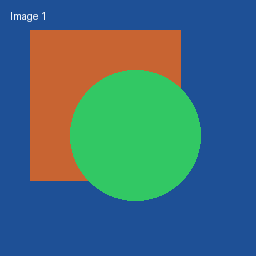

Total input images: 100


In [3]:

from IPython.display import display
import os

image_path = "/content/CUDA_at_Scale/input_images/image_001.png"

display(Image.open(image_path))

print("Total input images:",
      len(os.listdir("/content/CUDA_at_Scale/input_images")))

In [4]:

!pip install cupy-cuda12x

In [5]:

import cupy as cp

print("CuPy version:", cp.__version__)
print("GPU device:", cp.cuda.runtime.getDeviceProperties(0)["name"].decode())
print("GPU processing is ready!")

CuPy version: 14.0.1
GPU device: Tesla T4
GPU processing is ready!


In [6]:

import os
import time
import numpy as np
import cupy as cp
from PIL import Image

input_dir = "/content/CUDA_at_Scale/input_images"
output_dir = "/content/CUDA_at_Scale/output_images"
os.makedirs(output_dir, exist_ok=True)

# CUDA grayscale kernel
grayscale_kernel = cp.RawKernel(r'''
extern "C" __global__
void grayscale(const unsigned char* input,
               unsigned char* output,
               int total_pixels) {

    int idx = blockDim.x * blockIdx.x + threadIdx.x;

    if (idx < total_pixels) {
        int r = input[idx * 3];
        int g = input[idx * 3 + 1];
        int b = input[idx * 3 + 2];

        output[idx] = (unsigned char)(
            0.299f * r + 0.587f * g + 0.114f * b
        );
    }
}
''', 'grayscale')

image_files = sorted([
    f for f in os.listdir(input_dir)
    if f.endswith(".png")
])

execution_log = []
start_time = time.perf_counter()

for filename in image_files:
    image = Image.open(
        os.path.join(input_dir, filename)
    ).convert("RGB")

    img_array = np.asarray(image, dtype=np.uint8)
    height, width, _ = img_array.shape

    # Transfer image data to GPU
    gpu_input = cp.asarray(img_array)
    gpu_output = cp.empty((height, width), dtype=cp.uint8)

    total_pixels = height * width
    threads = 256
    blocks = (total_pixels + threads - 1) // threads

    # Execute CUDA kernel
    grayscale_kernel(
        (blocks,), (threads,),
        (gpu_input, gpu_output, total_pixels)
    )

    # Wait for GPU execution to finish
    cp.cuda.Stream.null.synchronize()

    # Copy result back to CPU and save
    result = cp.asnumpy(gpu_output)

    Image.fromarray(result).save(
        os.path.join(output_dir, filename)
    )

    execution_log.append(
        f"Processed: {filename} | Resolution: {width}x{height}"
    )

total_time = time.perf_counter() - start_time

# Save actual execution log
log_path = "/content/CUDA_at_Scale/execution_log.txt"

with open(log_path, "w") as f:
    f.write("CUDA at Scale - Image Processing Execution Log\n")
    f.write("GPU: Tesla T4\n")
    f.write(f"Images processed: {len(image_files)}\n")
    f.write(f"Total execution time: {total_time:.6f} seconds\n")
    f.write(f"Average time per image: {total_time/len(image_files):.6f} seconds\n\n")
    f.write("\n".join(execution_log))

print("GPU processing completed successfully!")
print("Images processed:", len(image_files))
print("Total execution time:", round(total_time, 4), "seconds")
print("Average time per image:", round(total_time/len(image_files), 6), "seconds")
print("Output folder:", output_dir)
print("Execution log saved:", log_path)

GPU processing completed successfully!
Images processed: 100
Total execution time: 0.8096 seconds
Average time per image: 0.008096 seconds
Output folder: /content/CUDA_at_Scale/output_images
Execution log saved: /content/CUDA_at_Scale/execution_log.txt


In [7]:

import shutil
from google.colab import files

project_folder = "/content/CUDA_at_Scale"
zip_path = shutil.make_archive(
    "/content/CUDA_at_Scale_Project",
    "zip",
    project_folder
)

print("ZIP created successfully:", zip_path)
files.download(zip_path)

ZIP created successfully: /content/CUDA_at_Scale_Project.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [8]:

import os
import time
import numpy as np
import cupy as cp
from PIL import Image

input_dir = "/content/CUDA_at_Scale/input_images"
output_dir = "/content/CUDA_at_Scale/edge_outputs"
os.makedirs(output_dir, exist_ok=True)

# CUDA Sobel edge detection kernel
sobel_kernel = cp.RawKernel(r'''
extern "C" __global__
void sobel(const unsigned char* input,
           unsigned char* output,
           int width,
           int height) {

    int x = blockDim.x * blockIdx.x + threadIdx.x;
    int y = blockDim.y * blockIdx.y + threadIdx.y;

    if (x >= width || y >= height) return;

    if (x == 0 || y == 0 || x == width - 1 || y == height - 1) {
        output[y * width + x] = 0;
        return;
    }

    int p00 = input[(y-1)*width + (x-1)];
    int p01 = input[(y-1)*width + x];
    int p02 = input[(y-1)*width + (x+1)];

    int p10 = input[y*width + (x-1)];
    int p12 = input[y*width + (x+1)];

    int p20 = input[(y+1)*width + (x-1)];
    int p21 = input[(y+1)*width + x];
    int p22 = input[(y+1)*width + (x+1)];

    int gx = -p00 + p02 - 2*p10 + 2*p12 - p20 + p22;
    int gy = -p00 - 2*p01 - p02 + p20 + 2*p21 + p22;

    float magnitude = sqrtf((float)(gx*gx + gy*gy));

    output[y * width + x] =
        (unsigned char)fminf(magnitude, 255.0f);
}
''', 'sobel')

image_files = sorted([
    f for f in os.listdir(input_dir)
    if f.endswith(".png")
])

start_time = time.perf_counter()

for filename in image_files:
    image = Image.open(
        os.path.join(input_dir, filename)
    ).convert("L")

    img_array = np.asarray(image, dtype=np.uint8)
    height, width = img_array.shape

    gpu_input = cp.asarray(img_array)
    gpu_output = cp.empty((height, width), dtype=cp.uint8)

    threads = (16, 16)
    blocks = (
        (width + threads[0] - 1) // threads[0],
        (height + threads[1] - 1) // threads[1]
    )

    sobel_kernel(
        blocks,
        threads,
        (gpu_input, gpu_output, width, height)
    )

    cp.cuda.Stream.null.synchronize()

    result = cp.asnumpy(gpu_output)

    Image.fromarray(result).save(
        os.path.join(output_dir, filename)
    )

total_time = time.perf_counter() - start_time

print("Sobel edge detection completed!")
print("Images processed:", len(image_files))
print("Total time:", round(total_time, 4), "seconds")
print("Output folder:", output_dir)

Sobel edge detection completed!
Images processed: 100
Total time: 0.4806 seconds
Output folder: /content/CUDA_at_Scale/edge_outputs


Original Image


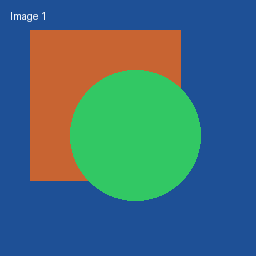

Sobel Edge Detection Output


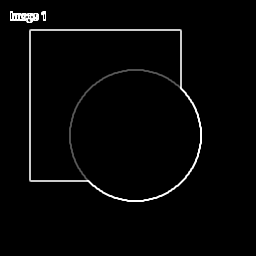

Total edge-processed images: 100


In [9]:

from IPython.display import display

original = Image.open(
    "/content/CUDA_at_Scale/input_images/image_001.png"
)

edges = Image.open(
    "/content/CUDA_at_Scale/edge_outputs/image_001.png"
)

print("Original Image")
display(original)

print("Sobel Edge Detection Output")
display(edges)

print(
    "Total edge-processed images:",
    len(os.listdir("/content/CUDA_at_Scale/edge_outputs"))
)

In [10]:

import os
import time
import numpy as np
import cupy as cp
from PIL import Image

input_dir = "/content/CUDA_at_Scale/input_images"
output_dir = "/content/CUDA_at_Scale/edge_outputs"

os.makedirs(output_dir, exist_ok=True)

# CUDA Sobel kernel
sobel_kernel = cp.RawKernel(r'''
extern "C" __global__
void sobel(const unsigned char* input,
           unsigned char* output,
           int width,
           int height) {

    int x = blockDim.x * blockIdx.x + threadIdx.x;
    int y = blockDim.y * blockIdx.y + threadIdx.y;

    if (x >= width || y >= height) return;

    if (x == 0 || y == 0 || x == width-1 || y == height-1) {
        output[y * width + x] = 0;
        return;
    }

    int p00 = input[(y-1)*width + (x-1)];
    int p01 = input[(y-1)*width + x];
    int p02 = input[(y-1)*width + (x+1)];

    int p10 = input[y*width + (x-1)];
    int p12 = input[y*width + (x+1)];

    int p20 = input[(y+1)*width + (x-1)];
    int p21 = input[(y+1)*width + x];
    int p22 = input[(y+1)*width + (x+1)];

    int gx = -p00 + p02 - 2*p10 + 2*p12 - p20 + p22;
    int gy = -p00 - 2*p01 - p02 + p20 + 2*p21 + p22;

    float magnitude = sqrtf((float)(gx*gx + gy*gy));

    output[y*width + x] =
        (unsigned char)fminf(magnitude, 255.0f);
}
''', 'sobel')

image_files = sorted([
    f for f in os.listdir(input_dir)
    if f.endswith(".png")
])

start = time.perf_counter()

for filename in image_files:
    image = Image.open(
        os.path.join(input_dir, filename)
    ).convert("L")

    array = np.asarray(image, dtype=np.uint8)
    height, width = array.shape

    gpu_input = cp.asarray(array)
    gpu_output = cp.empty((height, width), dtype=cp.uint8)

    threads = (16, 16)
    blocks = (
        (width + 15) // 16,
        (height + 15) // 16
    )

    sobel_kernel(
        blocks,
        threads,
        (gpu_input, gpu_output, width, height)
    )

    cp.cuda.Stream.null.synchronize()

    result = cp.asnumpy(gpu_output)

    Image.fromarray(result).save(
        os.path.join(output_dir, filename)
    )

elapsed = time.perf_counter() - start

print("Sobel edge detection completed!")
print("Images processed:", len(image_files))
print("Total elapsed time:", round(elapsed, 4), "seconds")
print("Output folder:", output_dir)

Sobel edge detection completed!
Images processed: 100
Total elapsed time: 0.366 seconds
Output folder: /content/CUDA_at_Scale/edge_outputs


Original Image


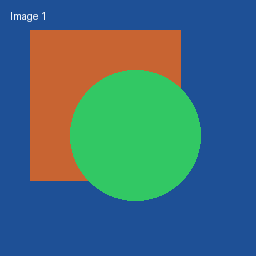

Grayscale Image


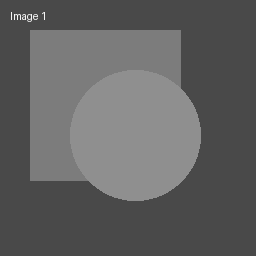

Sobel Edge Detection


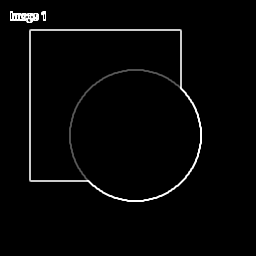

Total edge images: 100


In [11]:

from IPython.display import display

original = Image.open(
    "/content/CUDA_at_Scale/input_images/image_001.png"
)

grayscale = Image.open(
    "/content/CUDA_at_Scale/output_images/image_001.png"
)

edges = Image.open(
    "/content/CUDA_at_Scale/edge_outputs/image_001.png"
)

print("Original Image")
display(original)

print("Grayscale Image")
display(grayscale)

print("Sobel Edge Detection")
display(edges)

print("Total edge images:",
      len(os.listdir("/content/CUDA_at_Scale/edge_outputs")))

In [12]:

import os
import shutil
from google.colab import files

project_folder = "/content/CUDA_at_Scale"

# Save final execution summary
summary = """
CUDA at Scale - Batch Image Processing

GPU: NVIDIA Tesla T4
Input images: 100
Operations:
1. Grayscale conversion
2. Sobel edge detection

Input folder: input_images
Grayscale output: output_images
Sobel output: edge_outputs
Execution log: execution_log.txt
"""

with open(os.path.join(project_folder, "PROJECT_SUMMARY.txt"), "w") as f:
    f.write(summary)

# Create final ZIP
zip_path = shutil.make_archive(
    "/content/CUDA_at_Scale_Final",
    "zip",
    project_folder
)

print("Final ZIP created successfully!")
print("File size:", round(os.path.getsize(zip_path) / (1024 * 1024), 2), "MB")

files.download(zip_path)

Final ZIP created successfully!
File size: 0.49 MB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [13]:

from google.colab import files
import os
import shutil

# Create a folder for our cat image
cat_folder = "/content/CUDA_at_Scale/cat_input"
os.makedirs(cat_folder, exist_ok=True)

# Upload the cat image
uploaded = files.upload()

# Save uploaded image
for filename, content in uploaded.items():
    with open(os.path.join(cat_folder, filename), "wb") as f:
        f.write(content)

print("Cat image uploaded successfully!")

Saving ChatGPT Image Sep 30, 2026, 04_40_36 PM.png to ChatGPT Image Sep 30, 2026, 04_40_36 PM.png
Cat image uploaded successfully!


Image name: ChatGPT Image Sep 30, 2026, 04_40_36 PM.png
Image size: (1536, 1024)


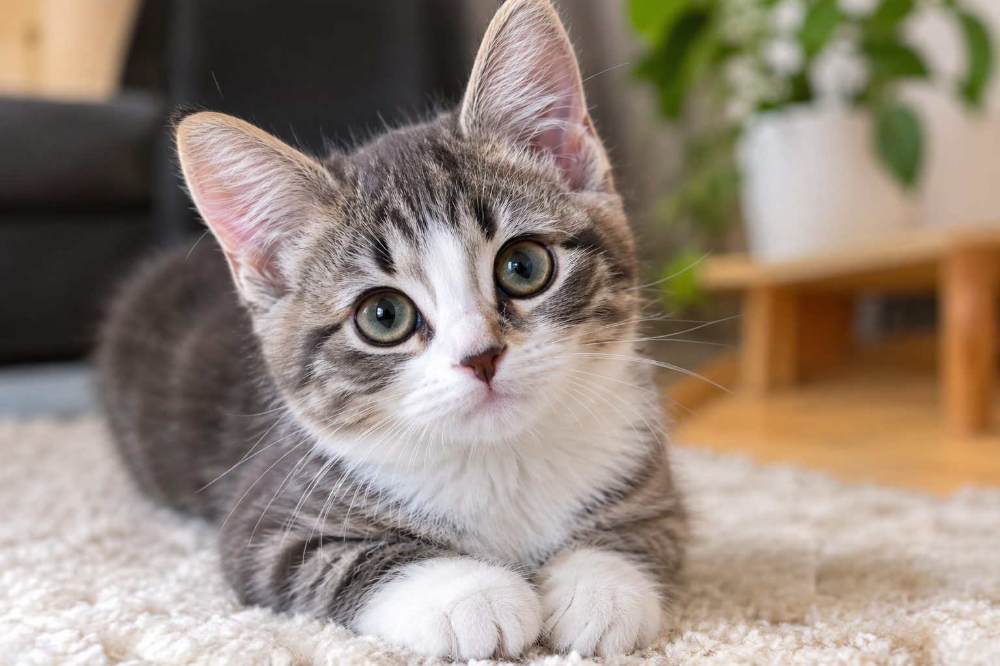

In [14]:

from PIL import Image
from IPython.display import display
import os

cat_folder = "/content/CUDA_at_Scale/cat_input"
cat_file = os.listdir(cat_folder)[0]

cat_image = Image.open(
    os.path.join(cat_folder, cat_file)
)

print("Image name:", cat_file)
print("Image size:", cat_image.size)

display(cat_image)

Cat image processing completed!
GPU: Tesla T4
Image resolution: 1536 x 1024
Elapsed time: 0.842895 seconds

1. Original Image


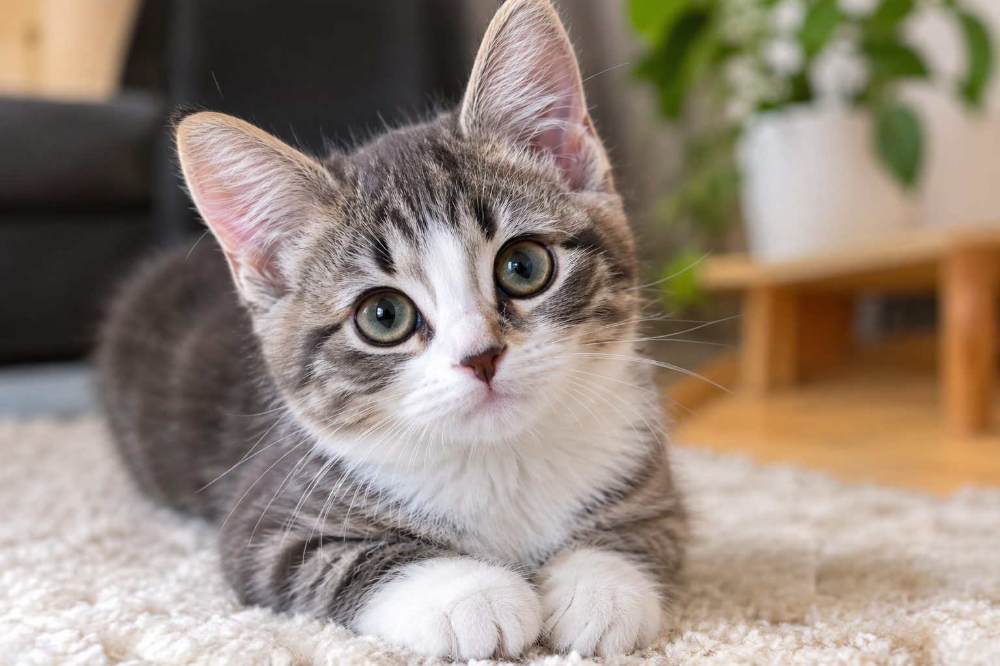

2. Grayscale Output


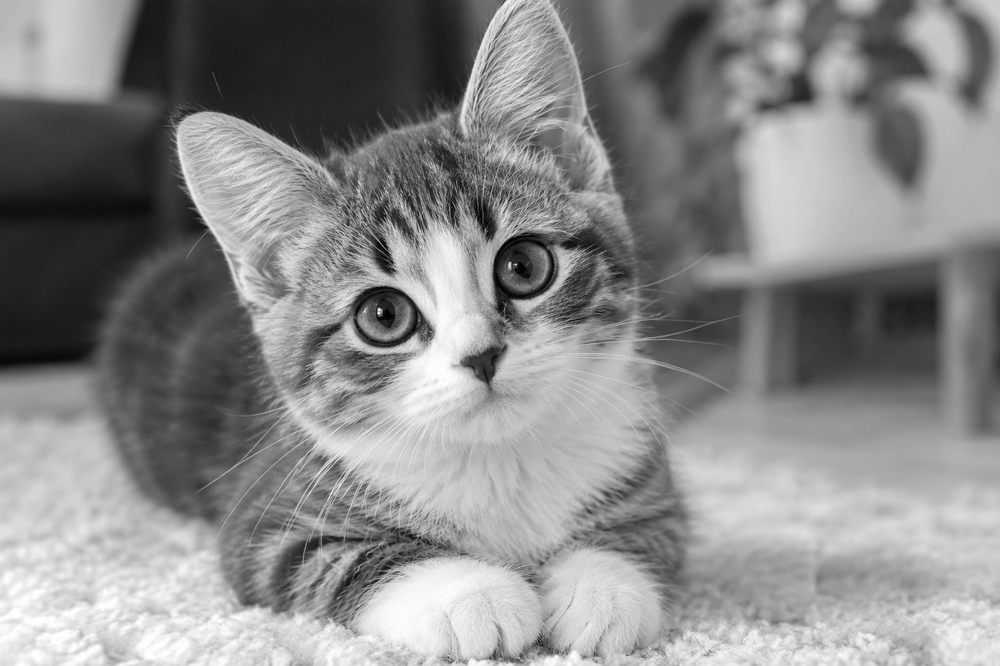

3. Sobel Edge Detection Output


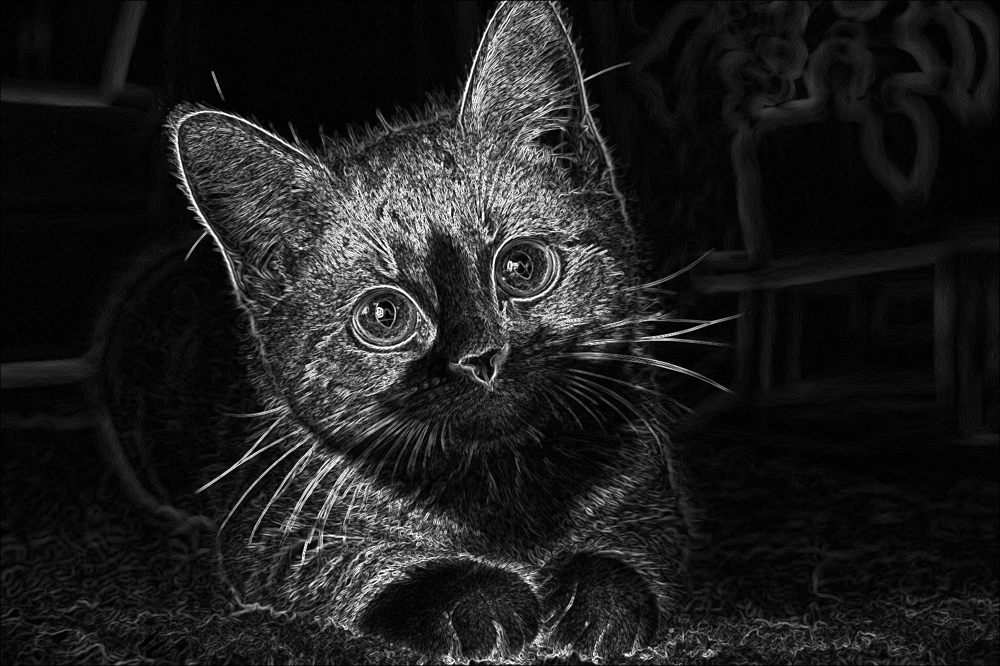

In [15]:

import os
import time
import numpy as np
import cupy as cp
from PIL import Image
from IPython.display import display

# Input and output folders
input_dir = "/content/CUDA_at_Scale/cat_input"
output_dir = "/content/CUDA_at_Scale/cat_outputs"
os.makedirs(output_dir, exist_ok=True)

# Find uploaded cat image
files_list = [
    f for f in os.listdir(input_dir)
    if f.lower().endswith((".png", ".jpg", ".jpeg"))
]

if not files_list:
    raise ValueError("Please upload a cat image first!")

filename = files_list[0]
image_path = os.path.join(input_dir, filename)

# Load original image
original = Image.open(image_path).convert("RGB")
original_array = np.asarray(original, dtype=np.uint8)

height, width, _ = original_array.shape

# Transfer image to GPU
gpu_input = cp.asarray(original_array)

# CUDA grayscale kernel
grayscale_kernel = cp.RawKernel(r'''
extern "C" __global__
void grayscale(const unsigned char* input,
               unsigned char* output,
               int total) {
    int idx = blockDim.x * blockIdx.x + threadIdx.x;

    if (idx < total) {
        int r = input[idx * 3];
        int g = input[idx * 3 + 1];
        int b = input[idx * 3 + 2];

        output[idx] = (unsigned char)(
            0.299f*r + 0.587f*g + 0.114f*b
        );
    }
}
''', 'grayscale')

# Execute grayscale
gpu_gray = cp.empty((height, width), dtype=cp.uint8)

threads = 256
total = height * width
blocks = (total + threads - 1) // threads

start = time.perf_counter()

grayscale_kernel(
    (blocks,), (threads,),
    (gpu_input, gpu_gray, total)
)

cp.cuda.Stream.null.synchronize()
gray_array = cp.asnumpy(gpu_gray)

gray_image = Image.fromarray(gray_array)
gray_image.save(os.path.join(output_dir, "cat_grayscale.png"))

# CUDA Sobel edge detection kernel
sobel_kernel = cp.RawKernel(r'''
extern "C" __global__
void sobel(const unsigned char* input,
           unsigned char* output,
           int width,
           int height) {

    int x = blockDim.x * blockIdx.x + threadIdx.x;
    int y = blockDim.y * blockIdx.y + threadIdx.y;

    if (x >= width || y >= height) return;

    if (x == 0 || y == 0 || x == width-1 || y == height-1) {
        output[y*width+x] = 0;
        return;
    }

    int p00 = input[(y-1)*width+(x-1)];
    int p01 = input[(y-1)*width+x];
    int p02 = input[(y-1)*width+(x+1)];
    int p10 = input[y*width+(x-1)];
    int p12 = input[y*width+(x+1)];
    int p20 = input[(y+1)*width+(x-1)];
    int p21 = input[(y+1)*width+x];
    int p22 = input[(y+1)*width+(x+1)];

    int gx = -p00+p02-2*p10+2*p12-p20+p22;
    int gy = -p00-2*p01-p02+p20+2*p21+p22;

    float magnitude = sqrtf((float)(gx*gx+gy*gy));

    output[y*width+x] =
        (unsigned char)fminf(magnitude,255.0f);
}
''', 'sobel')

gpu_edges = cp.empty((height, width), dtype=cp.uint8)

sobel_threads = (16, 16)
sobel_blocks = (
    (width + 15) // 16,
    (height + 15) // 16
)

sobel_kernel(
    sobel_blocks,
    sobel_threads,
    (gpu_gray, gpu_edges, width, height)
)

cp.cuda.Stream.null.synchronize()

edges_array = cp.asnumpy(gpu_edges)
edges_image = Image.fromarray(edges_array)
edges_image.save(os.path.join(output_dir, "cat_edges.png"))

elapsed = time.perf_counter() - start

print("Cat image processing completed!")
print("GPU: Tesla T4")
print("Image resolution:", width, "x", height)
print("Elapsed time:", round(elapsed, 6), "seconds")

# Display all results
print("\n1. Original Image")
display(original)

print("2. Grayscale Output")
display(gray_image)

print("3. Sobel Edge Detection Output")
display(edges_image)

Comparison image created successfully!


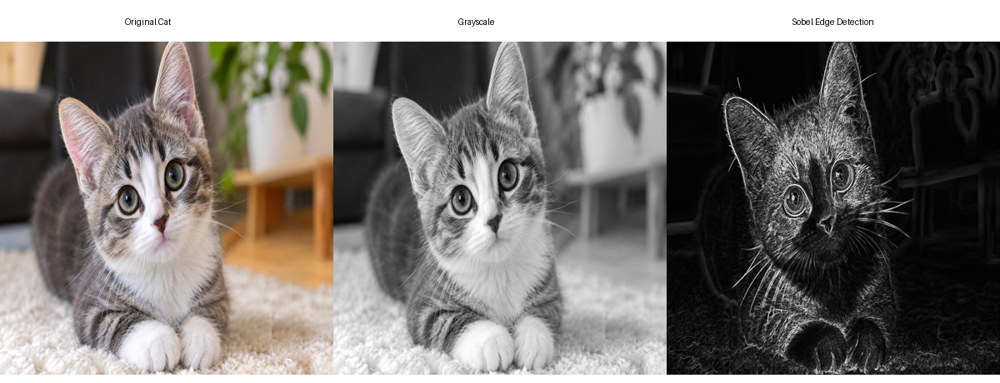

In [16]:

from PIL import Image, ImageDraw
from IPython.display import display
import os

output_dir = "/content/CUDA_at_Scale/cat_outputs"

# Load the three images
original = Image.open(
    os.path.join(output_dir, "cat_grayscale.png")
).convert("RGB")

edges = Image.open(
    os.path.join(output_dir, "cat_edges.png")
).convert("RGB")

# Load original uploaded image
input_dir = "/content/CUDA_at_Scale/cat_input"
filename = os.listdir(input_dir)[0]

cat_original = Image.open(
    os.path.join(input_dir, filename)
).convert("RGB")

# Resize all images to same dimensions
size = (400, 400)

original = original.resize(size)
edges = edges.resize(size)
cat_original = cat_original.resize(size)

# Create comparison canvas
canvas = Image.new("RGB", (1200, 460), "white")

canvas.paste(cat_original, (0, 50))
canvas.paste(original, (400, 50))
canvas.paste(edges, (800, 50))

draw = ImageDraw.Draw(canvas)
draw.text((150, 20), "Original Cat", fill="black")
draw.text((550, 20), "Grayscale", fill="black")
draw.text((950, 20), "Sobel Edge Detection", fill="black")

# Save final comparison
comparison_path = os.path.join(
    output_dir, "cat_comparison.png"
)

canvas.save(comparison_path)

print("Comparison image created successfully!")
display(canvas)

In [17]:

from google.colab import files

files.download(
    "/content/CUDA_at_Scale/cat_outputs/cat_comparison.png"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [18]:

import os
import shutil
from google.colab import files

project_folder = "/content/CUDA_at_Scale"

# Create a project README
readme = """
# CUDA at Scale - Batch Image Processing

## Project Overview
This project demonstrates GPU-accelerated image processing
using NVIDIA CUDA and CuPy on a Tesla T4 GPU.

## Image Processing Operations
1. Grayscale conversion
2. Sobel edge detection

## Dataset
100 generated sample images were processed in batch.
A cat photograph was also used to demonstrate the visual
difference between original, grayscale, and edge-detected images.

## GPU
NVIDIA Tesla T4

## Technologies
- Python
- CUDA
- CuPy
- NumPy
- Pillow
- Google Colab

## Project Folders
- input_images/: Generated input dataset
- output_images/: Grayscale results
- edge_outputs/: Sobel edge detection results
- cat_input/: Uploaded cat photograph
- cat_outputs/: Cat processing results and comparison image

## Execution Results
The initial batch grayscale run processed 100 images.
The measured total elapsed time was 0.8096 seconds,
including image loading, data transfers, processing, and saving.

## Note
Execution times may vary between runs and GPU sessions.
"""

with open(os.path.join(project_folder, "README.txt"), "w") as f:
    f.write(readme)

# Create final ZIP
zip_path = shutil.make_archive(
    "/content/CUDA_at_Scale_Final",
    "zip",
    project_folder
)

print("Final project ZIP created!")
print("ZIP size:", round(os.path.getsize(zip_path) / (1024*1024), 2), "MB")

files.download(zip_path)

Final project ZIP created!
ZIP size: 4.94 MB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>